# Homework 4

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
!wget $data -O 'homework4.csv'

--2026-10-15 06:54:27--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘homework4.csv’

homework4.csv       100%[===================>] 272.21K  --.-KB/s    in 0.005s  

2026-10-15 06:54:27 (50.0 MB/s) - ‘homework4.csv’ saved [278746/278746]



In [4]:
df = pd.read_csv('homework4.csv')

In [5]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [11]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [10]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [12]:
for c in categorical:
    df[c] = df[c].fillna('NA')
for c in numerical:
    df[c] = df[c].fillna(0)

In [13]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [15]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

## Q1

In [17]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [18]:
from sklearn.metrics import roc_auc_score

In [21]:
y_train

array([1, 0, 0, ..., 0, 1, 1], shape=(3000,))

In [22]:
for c in numerical:

    score = roc_auc_score(y_train,df_train[c])
    print(c,score)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


## Q2

In [23]:
def train(df,y):
    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y)
    return dv,model

In [24]:
def predict(df,dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:,1]
    return y_pred

In [25]:
dv, model = train(df_train,y_train)
y_pred = predict(df_val,dv,model)
print(round(roc_auc_score(y_val,y_pred),3))

0.732


## Q3

In [28]:
thresholds = np.linspace(0.0,1.0,101)
p_list = []
r_list = []
for t in thresholds:
    predict_positive = (y_pred >=t)
    predict_negative = (y_pred <t)

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    tp = (actual_positive & predict_positive).sum()
    tn = (actual_negative & predict_negative).sum()
    fp = (actual_negative & predict_positive).sum()
    fn = (actual_positive & predict_negative).sum()

    p = tp / (tp + fp)
    r = tp / (tp + fn)

    p_list.append(p)
    r_list.append(r)

/tmp/ipykernel_88026/3061211450.py:15: RuntimeWarning: invalid value encountered in scalar divide
  p = tp / (tp + fp)


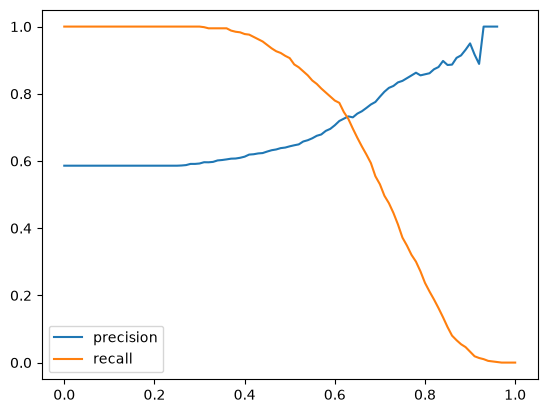

In [30]:
plt.plot(thresholds,p_list,label='precision')
plt.plot(thresholds,r_list,label='recall')
plt.legend()

In [31]:
for i in range(50,70):
    print(thresholds[i],p_list[i]-r_list[i])

0.5 -0.262506981073534
0.51 -0.2406058444976482
0.52 -0.22940705576524967
0.53 -0.2088631098693169
0.54 -0.19312581999179435
0.55 -0.17201920895059297
0.56 -0.15435153583617744
0.5700000000000001 -0.136722385975799
0.58 -0.11414958099930539
0.59 -0.09615669980709307
0.6 -0.07352654150687599
0.61 -0.05398992361449695
0.62 -0.01982016713344592
0.63 0.007502647993409384
0.64 0.03362904259800836
0.65 0.07207881442866637
0.66 0.10467116311826208
0.67 0.1383748851062011
0.68 0.17435526523969902
0.6900000000000001 0.22104881604991566


## Q4

In [32]:
f1_list = []

for i in range(101):
    f1 = 2*p_list[i]*r_list[i]/(p_list[i]+r_list[i])
    f1_list.append(f1)

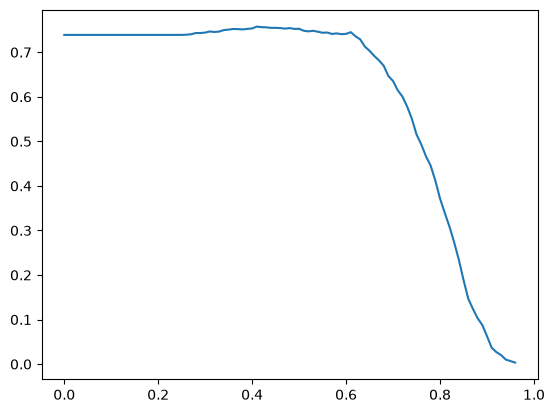

In [33]:
plt.plot(thresholds,f1_list)

In [34]:
idx = np.nanargmax(f1_list)

In [35]:
print(idx)

41


## Q5

In [36]:
from sklearn.model_selection import KFold

In [37]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [40]:
scores =[]

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv,model = train(df_train, y_train)
    y_pred = predict(df_val,dv,model)

    score = roc_auc_score(y_val,y_pred)
    scores.append(score)

print(np.std(scores))

0.006853233151022138


## Q6

In [41]:
def train_C(df,y,C):
    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y)
    return dv,model

In [42]:
C_list = [0.000001, 0.001, 1]

for C in C_list:

    scores =[]
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.converted.values
        y_val = df_val.converted.values
    
        dv,model = train_C(df_train, y_train,C=C)
        y_pred = predict(df_val,dv,model)
    
        score = roc_auc_score(y_val,y_pred)
        scores.append(score)
    
    print(C,round(np.mean(scores),3))

1e-06 0.617
0.001 0.749
1 0.732
